In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
tuatha_nw_1600_mod = gpd.read_file("/home/dylanf/Documents/GitHub/data/Files1600/tuatha_nw_1600_mod.shp")


In [3]:
# Calculate a contiguity matrix based on queen contiguity
from libpysal.weights import Queen

airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)
airecht_w.transform = 'r'
airecht_w

/tmp/ipykernel_85384/1118973650.py:4: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)


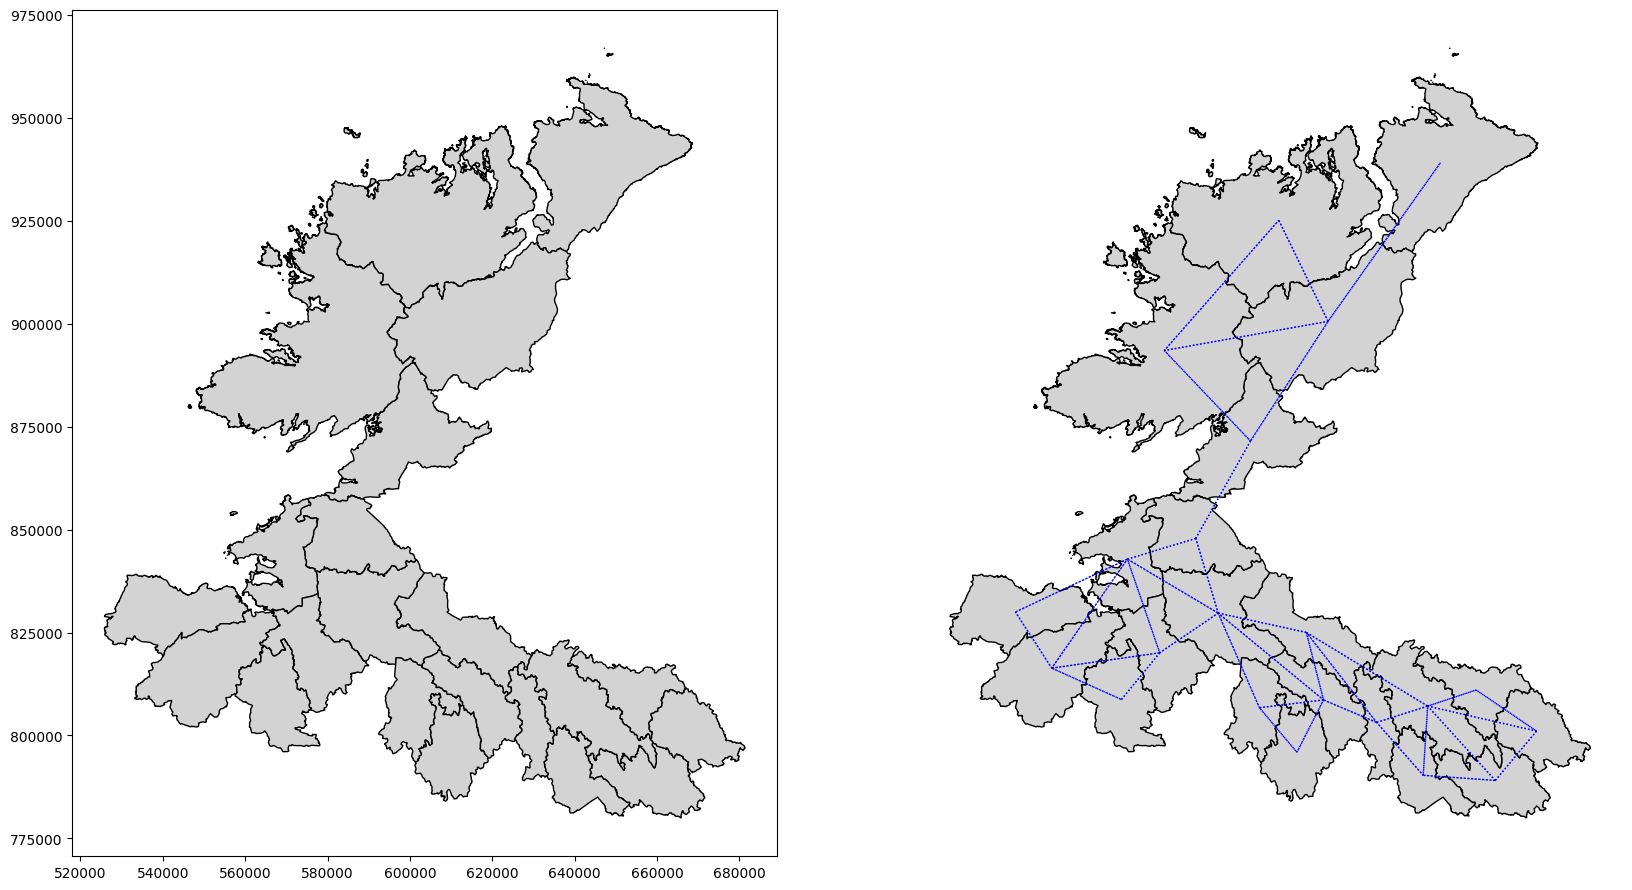

In [7]:
f, axs = plt.subplots(1, 2, figsize=(20, 20))
for i in range(2):
    ax = tuatha_nw_1600_mod.plot(
        edgecolor="k", facecolor="lightgray", ax=axs[i]
    )
airecht_w.plot(
    tuatha_nw_1600_mod,
    ax = axs[i],
    edge_kws=dict(color="b", linestyle=":", linewidth=1),       
    node_kws=dict(marker="")),

axs[i].set_axis_off()

In [5]:
# Print all territory names to find the correct spelling
print("Available territory names:")
print(tuatha_nw_1600_mod['ENGLISH'].unique())

Available territory names:
['TIRHUGH' 'TULLYHAW' 'TULLYGARVEY' 'DRUMAHAIRE' 'CASTLERAHAN'
 'KILMACRENAN' 'CLANMAHON' 'LEITRIM' 'CLANKEE' 'TIRERAGH' 'TULLYHUNCO'
 'ROSCLOGHER' 'LEYNY' 'CARBURY' 'TIRERRILL' 'MOHILL' 'CARRIGALLEN'
 'INISHOWEN' 'RAPHOE' 'CORANN' 'LOUGHTEE' 'BOYLAGH']


In [6]:
# Create helper function to safely get territory indices
def get_territory_index(df, territory_name):
    territory = df[df['ENGLISH'] == territory_name]
    if len(territory) == 0:
        print(f"Warning: Territory '{territory_name}' not found!")
        return None
    return territory.index[0]

# Create the initial queen weights
airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)

# Get the indices for the territories we want to connect
carbury_idx = get_territory_index(tuatha_nw_1600_mod, 'CARBURY')
tireragh_idx = get_territory_index(tuatha_nw_1600_mod, 'TIRERAGH')
leyney_idx = get_territory_index(tuatha_nw_1600_mod, 'LEYNY')  # Fixed spelling

# Only proceed with connections if we found all territories
if all(idx is not None for idx in [carbury_idx, tireragh_idx, leyney_idx]):
    # Add the missing connections
    airecht_w.neighbors[carbury_idx] = list(set(airecht_w.neighbors[carbury_idx] + [tireragh_idx, leyney_idx]))
    airecht_w.neighbors[tireragh_idx] = list(set(airecht_w.neighbors[tireragh_idx] + [carbury_idx]))
    airecht_w.neighbors[leyney_idx] = list(set(airecht_w.neighbors[leyney_idx] + [carbury_idx]))

    # Transform to row-standardized weights
    airecht_w.transform = 'r'

    # Verify the connections
    print(f"Carbury connections: {[tuatha_nw_1600_mod.iloc[i]['ENGLISH'] for i in airecht_w.neighbors[carbury_idx]]}")

Carbury connections: ['DRUMAHAIRE', 'TIRERAGH', 'ROSCLOGHER', 'LEYNY', 'TIRERRILL']


/tmp/ipykernel_85384/3727627446.py:10: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  airecht_w = Queen.from_dataframe(tuatha_nw_1600_mod)


/tmp/ipykernel_85384/1510460183.py:17: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()
/tmp/ipykernel_85384/1510460183.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


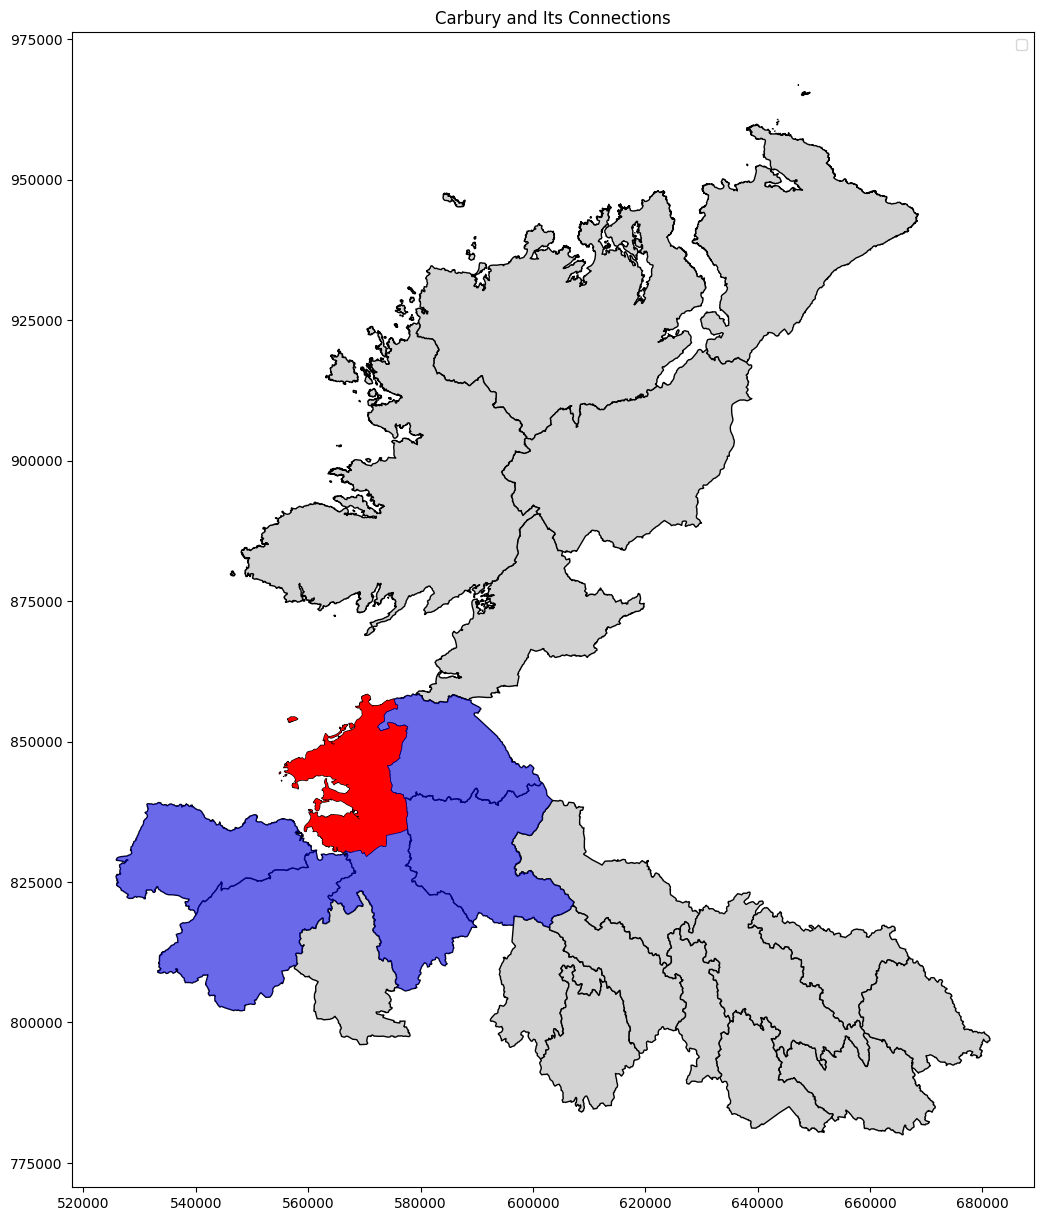

In [8]:
# Plot to verify the connections
fig, ax = plt.subplots(figsize=(15, 15))

# Plot all territories
tuatha_nw_1600_mod.plot(ax=ax, color='lightgrey', edgecolor='black')

# Highlight Carbury and its connections
carbury = tuatha_nw_1600_mod[tuatha_nw_1600_mod['ENGLISH'] == 'CARBURY']
connected_territories = tuatha_nw_1600_mod.iloc[airecht_w.neighbors[carbury_idx]]

# Plot Carbury in red
carbury.plot(ax=ax, color='red', label='Carbury')
# Plot connected territories in blue
connected_territories.plot(ax=ax, color='blue', alpha=0.5, label='Connected Territories')

plt.title('Carbury and Its Connections')
plt.legend()
plt.show()

In [9]:
# Add connection counts to the GeoDataFrame
tuatha_nw_1600_mod['connections'] = pd.Series(airecht_w.cardinalities)

# Save the enhanced GeoDataFrame
tuatha_nw_1600_mod.to_file("tuatha_nw_1600_mod_with_connections.shp")

# Let's verify the data
print("\nTerritories sorted by number of connections:")
print(tuatha_nw_1600_mod[['ENGLISH', 'connections', 'chief_king']].sort_values('connections', ascending=False))


Territories sorted by number of connections:
        ENGLISH  connections  chief_king
3    DRUMAHAIRE            6           1
20     LOUGHTEE            6           1
13      CARBURY            5           1
16  CARRIGALLEN            5           0
10   TULLYHUNCO            4           0
1      TULLYHAW            4           0
14    TIRERRILL            4           0
18       RAPHOE            4           1
12        LEYNY            4           0
0       TIRHUGH            3           0
21      BOYLAGH            3           0
11   ROSCLOGHER            3           0
4   CASTLERAHAN            3           0
6     CLANMAHON            3           0
8       CLANKEE            3           0
7       LEITRIM            3           0
5   KILMACRENAN            2           0
2   TULLYGARVEY            2           0
9      TIRERAGH            2           0
15       MOHILL            2           0
19       CORANN            2           0
17    INISHOWEN            1           0


/tmp/ipykernel_85384/3789592488.py:5: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  tuatha_nw_1600_mod.to_file("tuatha_nw_1600_mod_with_connections.shp")
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'connections' to 'connecti_1'
  ogr_write(
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Value 519751357.949999988 of field AREA of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Value 519758567.549896002 of field Shape__Are of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
/home/d

/tmp/ipykernel_85384/376976389.py:6: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  queen = Queen.from_dataframe(gdf)


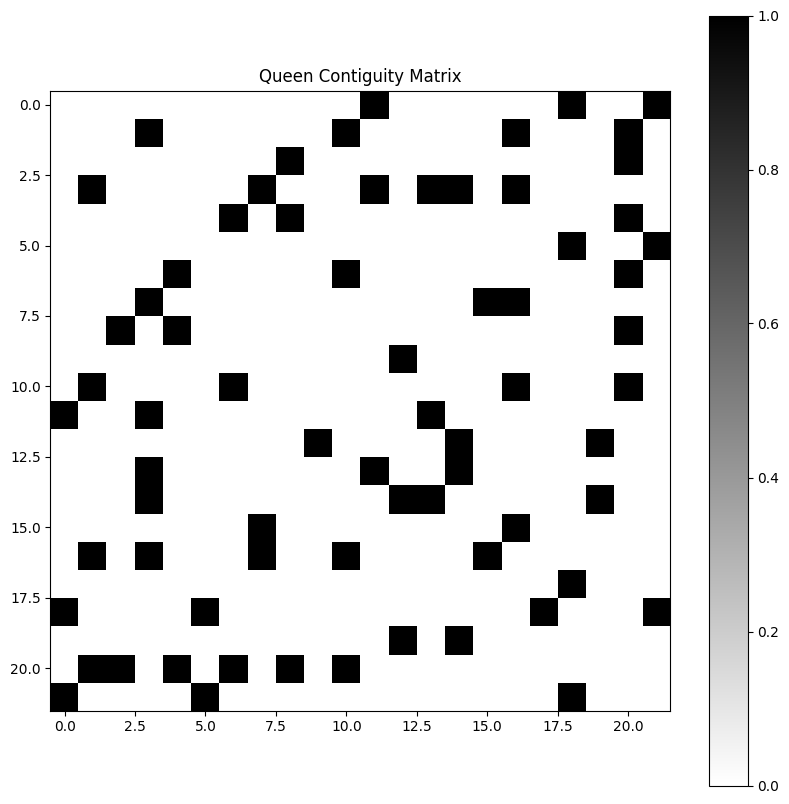

In [10]:
# First, read the shapefile using geopandas
gdf = gpd.read_file("tuatha_nw_1600_mod_with_connections.shp")

# Create queen weights using libpysal
from libpysal.weights import Queen
queen = Queen.from_dataframe(gdf)

# Convert weights object to a matrix
queen_matrix = queen.full()[0]  # [0] gets the actual matrix

# Display the matrix
plt.figure(figsize=(10, 10))
plt.imshow(queen_matrix, cmap='binary')
plt.colorbar()
plt.title('Queen Contiguity Matrix')
plt.show()

In [11]:
def add_chief_king_column(df):
    # Create binary column for chief kings
    df['chief_king'] = 0
    
    # Define chief king territories
    chief_territories = ['RAPHOE', 'CARBURY', 'DRUMAHAIRE', 'LOUGHTEE']
    df.loc[df['ENGLISH'].isin(chief_territories), 'chief_king'] = 1
    
    return df

# Save the updated GeoDataFrame back to file
tuatha_nw_1600_mod.to_file('/home/dylanf/Documents/GitHub/data/Files1600/tuatha_nw_1600_mod.shp')

# Verify the save
print("Columns in saved file:", tuatha_nw_1600_mod.columns.tolist())
print("\nChief king territories:")
print(tuatha_nw_1600_mod[tuatha_nw_1600_mod['chief_king'] == 1][['ENGLISH', 'chief_king']])



Columns in saved file: ['BY_ID', 'ENGLISH', 'GAEILGE', 'LOGAINM_ID', 'AIREACHT', 'FEDERATION', 'PROVINCE', 'GUID', 'CENTROID_X', 'CENTROID_Y', 'AREA', 'OBJECTID', 'Shape__Are', 'Shape__Len', 'connection', 'chief_king', 'geometry', 'connections']

Chief king territories:
       ENGLISH  chief_king
3   DRUMAHAIRE           1
13     CARBURY           1
18      RAPHOE           1
20    LOUGHTEE           1


/tmp/ipykernel_85384/121795587.py:12: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  tuatha_nw_1600_mod.to_file('/home/dylanf/Documents/GitHub/data/Files1600/tuatha_nw_1600_mod.shp')
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Normalized/laundered field name: 'connections' to 'connecti_1'
  ogr_write(
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Value 519751357.949999988 of field AREA of feature 0 not successfully written. Possibly due to too larger number with respect to field width
  ogr_write(
/home/dylanf/Documents/GitHub/Artefact/Colab/2025_Version_2/.venv/lib/python3.12/site-packages/pyogrio/raw.py:723: RuntimeWarning: Value 519758567.549896002 of field Shape__Are of feature 0 not successfully written. Possibly due to too larger number with respect to fiel

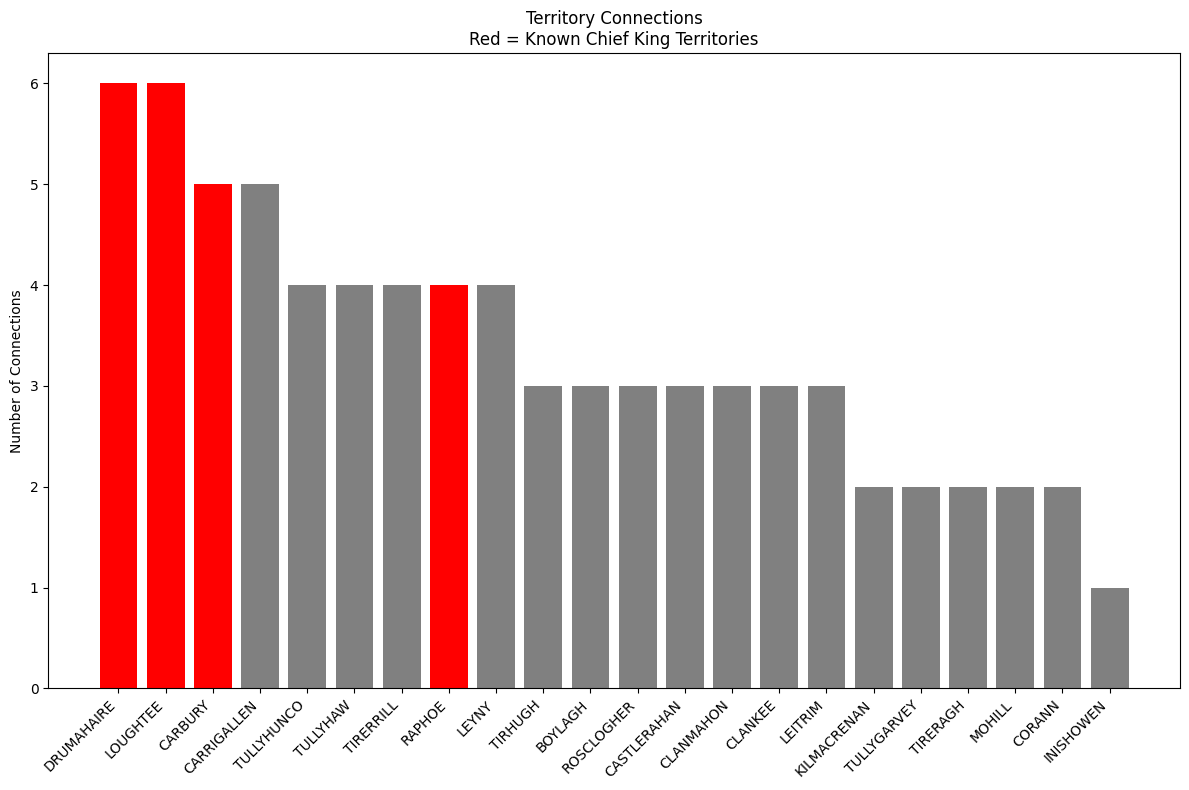

In [12]:
# Calculate number of connections for each territory
connection_counts = pd.Series(airecht_w.cardinalities)
tuatha_nw_1600_mod['connections'] = connection_counts

# Compare connections with known chief king territories
analysis_df = tuatha_nw_1600_mod[['ENGLISH', 'connections', 'chief_king']].copy()
analysis_df = analysis_df.sort_values('connections', ascending=False)

# Calculate correlation between connections and chief_king status
correlation = analysis_df['connections'].corr(analysis_df['chief_king'])

# Visualize the relationship
plt.figure(figsize=(12, 8))
plt.bar(range(len(analysis_df)), 
        analysis_df['connections'],
        color=analysis_df['chief_king'].map({0: 'grey', 1: 'red'}))
plt.xticks(range(len(analysis_df)), analysis_df['ENGLISH'], rotation=45, ha='right')
plt.title('Territory Connections\nRed = Known Chief King Territories')
plt.ylabel('Number of Connections')
plt.tight_layout()
plt.show()


Statistical Summary:
Correlation between connections and chief king status: 0.685

Average connections for chief king territories: 5.25
Average connections for other territories: 2.94

Mann-Whitney U test p-value: 0.003
(Tests if chief king territories have significantly more connections)


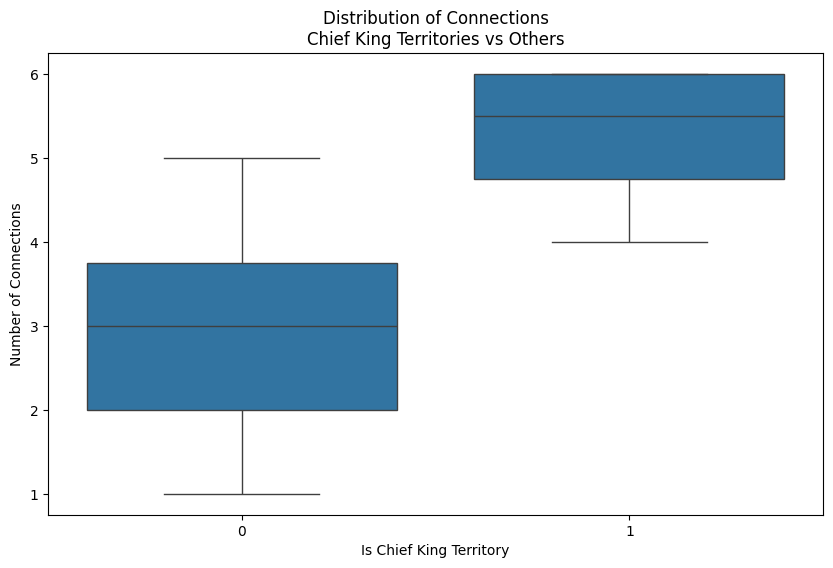

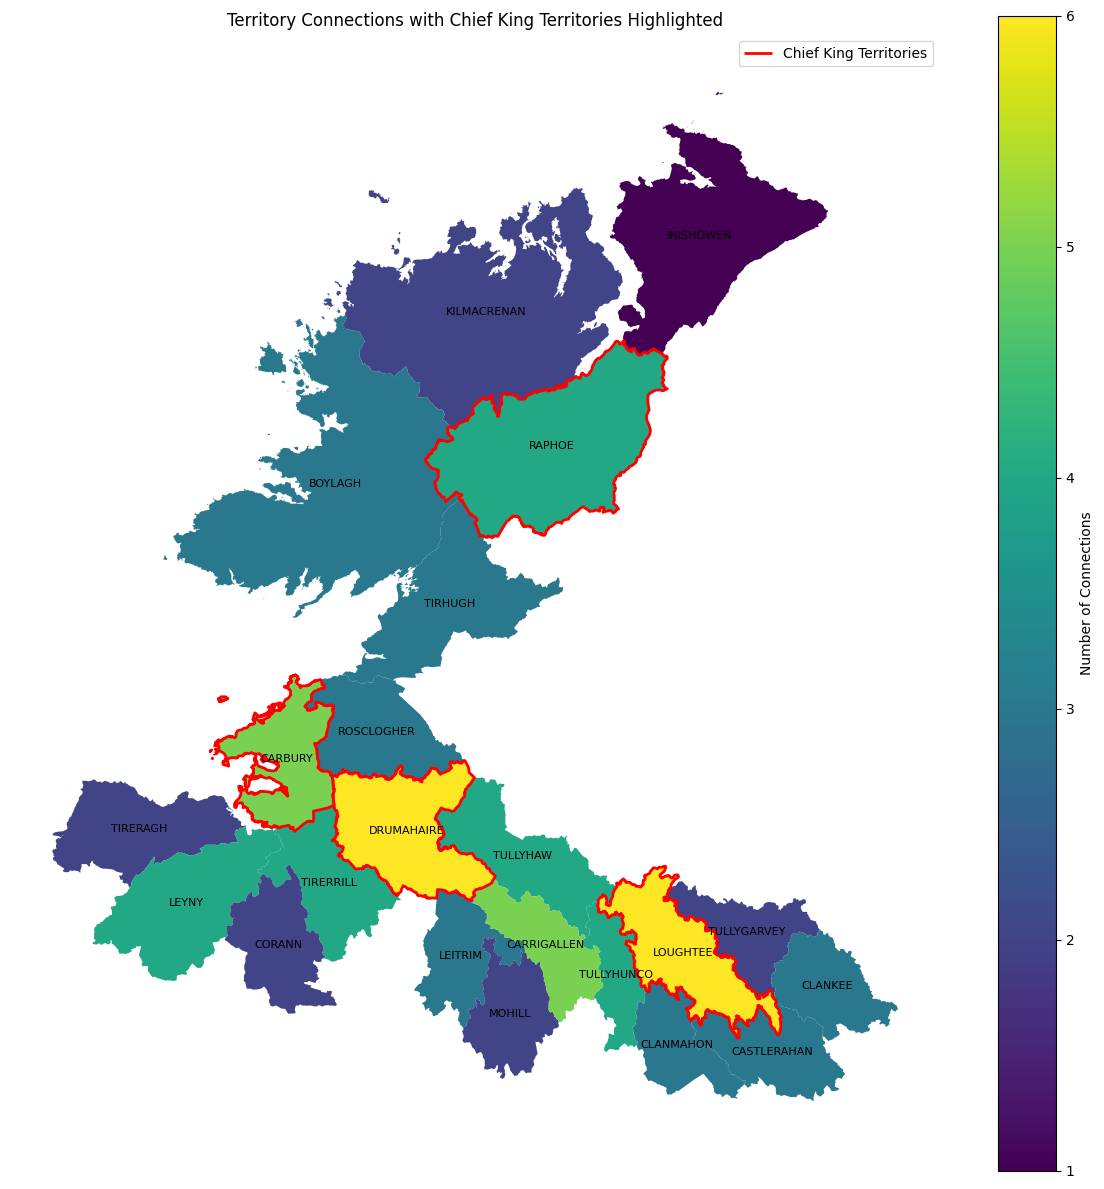


Predictive Power of Connection Counts:
Precision: 0.44
Recall: 1.00
Overall Accuracy: 0.77

Territory Analysis:

Correctly Identified Territories:
        ENGLISH  connections  chief_king
3    DRUMAHAIRE            6           1
20     LOUGHTEE            6           1
13      CARBURY            5           1
18       RAPHOE            4           1
0       TIRHUGH            3           0
21      BOYLAGH            3           0
11   ROSCLOGHER            3           0
4   CASTLERAHAN            3           0
6     CLANMAHON            3           0
8       CLANKEE            3           0
7       LEITRIM            3           0
5   KILMACRENAN            2           0
2   TULLYGARVEY            2           0
9      TIRERAGH            2           0
15       MOHILL            2           0
19       CORANN            2           0
17    INISHOWEN            1           0

Misclassified Territories:
        ENGLISH  connections  chief_king
16  CARRIGALLEN            5           0
10  

In [13]:
# 1. Basic Statistical Summary
print("\nStatistical Summary:")
print(f"Correlation between connections and chief king status: {correlation:.3f}")

# Calculate average connections for chief kings vs others
chief_avg = analysis_df[analysis_df['chief_king'] == 1]['connections'].mean()
other_avg = analysis_df[analysis_df['chief_king'] == 0]['connections'].mean()
print(f"\nAverage connections for chief king territories: {chief_avg:.2f}")
print(f"Average connections for other territories: {other_avg:.2f}")

# 2. Mann-Whitney U test (non-parametric test for difference between groups)
from scipy import stats

chief_connections = analysis_df[analysis_df['chief_king'] == 1]['connections']
other_connections = analysis_df[analysis_df['chief_king'] == 0]['connections']
statistic, p_value = stats.mannwhitneyu(chief_connections, other_connections, alternative='greater')

print(f"\nMann-Whitney U test p-value: {p_value:.3f}")
print("(Tests if chief king territories have significantly more connections)")

# 3. Create a box plot to show distribution comparison
plt.figure(figsize=(10, 6))
sns.boxplot(x='chief_king', y='connections', data=analysis_df)
plt.title('Distribution of Connections\nChief King Territories vs Others')
plt.xlabel('Is Chief King Territory')
plt.ylabel('Number of Connections')
plt.show()

# 4. Create a map visualization
fig, ax = plt.subplots(figsize=(15, 15))

# Plot territories with connection counts
tuatha_nw_1600_mod.plot(column='connections', 
                        ax=ax,
                        legend=True,
                        legend_kwds={'label': 'Number of Connections'},
                        cmap='viridis')

# Highlight chief king territories with bold boundaries
tuatha_nw_1600_mod[tuatha_nw_1600_mod['chief_king'] == 1].boundary.plot(
    ax=ax, color='red', linewidth=2, label='Chief King Territories')

# Add territory labels
for idx, row in tuatha_nw_1600_mod.iterrows():
    ax.annotate(text=row['ENGLISH'], 
                xy=(row.geometry.centroid.x, row.geometry.centroid.y),
                ha='center', va='center',
                fontsize=8)

plt.title('Territory Connections with Chief King Territories Highlighted')
plt.axis('off')
plt.legend()
plt.show()

# 5. Calculate and display predictive accuracy
# Using number of connections as a predictor
connection_threshold = analysis_df[analysis_df['chief_king'] == 1]['connections'].min()
predicted_chiefs = analysis_df['connections'] >= connection_threshold

# Calculate accuracy metrics
true_positives = sum((analysis_df['chief_king'] == 1) & (predicted_chiefs))
false_positives = sum((analysis_df['chief_king'] == 0) & (predicted_chiefs))
true_negatives = sum((analysis_df['chief_king'] == 0) & (~predicted_chiefs))
false_negatives = sum((analysis_df['chief_king'] == 1) & (~predicted_chiefs))

precision = true_positives / (true_positives + false_positives)
recall = true_positives / (true_positives + false_negatives)
accuracy = (true_positives + true_negatives) / len(analysis_df)

print("\nPredictive Power of Connection Counts:")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"Overall Accuracy: {accuracy:.2f}")

# 6. List territories by prediction accuracy
print("\nTerritory Analysis:")
analysis_df['predicted_chief'] = predicted_chiefs
analysis_df['prediction_correct'] = analysis_df['predicted_chief'] == analysis_df['chief_king']

print("\nCorrectly Identified Territories:")
print(analysis_df[analysis_df['prediction_correct']][['ENGLISH', 'connections', 'chief_king']])

print("\nMisclassified Territories:")
print(analysis_df[~analysis_df['prediction_correct']][['ENGLISH', 'connections', 'chief_king']])

In [29]:

# Get connection counts for chief king territories
chief_territories = analysis_df[analysis_df['chief_king'] == 1][['ENGLISH', 'connections']].sort_values('connections', ascending=False)
print("\nChief King Territory Connections:")
print(chief_territories)

# Get top 5 territories by connections
print("\nTop 5 Territories by Connections:")
print(analysis_df.nlargest(5, 'connections')[['ENGLISH', 'connections', 'chief_king']])



Chief King Territory Connections:
       ENGLISH  connections
3   DRUMAHAIRE            6
20    LOUGHTEE            6
13     CARBURY            5
18      RAPHOE            4

Top 5 Territories by Connections:
        ENGLISH  connections  chief_king
3    DRUMAHAIRE            6           1
20     LOUGHTEE            6           1
13      CARBURY            5           1
16  CARRIGALLEN            5           0
10   TULLYHUNCO            4           0


In [ ]:
lets create 